# Overview of the Results

This notebook gives a first overview of the results of the experiment.

The process consists of:
1. **Summary**: Counting the model runs per size category and operating mode, with the range of their results.
2. **Accuracy vs. Energy**: Plotting every model run by its accuracy and GPU energy per question.
3. **Pareto Front**: Listing the model runs on the Pareto front and finding its knee.
4. **Standout Models**: Identifying the model runs with the highest and lowest values.
5. **Total Energy**: Computing the energy consumed by each model run over all its repetitions.
6. **Repeatability**: Measuring the variation between the repetitions of each model run.
7. **Temperature of the Hardware**: Following the GPU and CPU temperature along the questions of a run and along the main execution.
8. **Key Values**: Printing the main values of this notebook.

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from common import (
    BUDGETS_KJ,
    CATEGORY_COLORS,
    CATEGORY_ORDER,
    FAMILY_ORDER,
    QUESTIONS,
    chance_level,
    legend_handles,
    load_inferences,
    load_model_runs,
    load_questions,
    load_repetitions,
    pareto_front,
    percent_axis,
    save_chart,
    scatter_model_runs,
    short_name,
)

model_runs = load_model_runs()
repetitions = load_repetitions(model_runs)
questions = load_questions(model_runs)
inferences = load_inferences(model_runs)

CHANCE_LEVEL = chance_level(questions)
FAMILIES = [family for family in FAMILY_ORDER if family in set(model_runs["family"])]

print(f"Model runs: {len(model_runs)}   models: {model_runs['model'].nunique()}   repetitions: {len(repetitions)}   inferences: {len(inferences)}")
print(f"Chance level of the benchmark sample: {CHANCE_LEVEL:.3f}")

Model runs: 53   models: 47   repetitions: 515   inferences: 191580
Chance level of the benchmark sample: 0.114


### 1. Summary of the Model Runs
Number of model runs in each size category and operating mode, with the range of their accuracy, GPU energy per question and generated tokens per question.

In [2]:
def low_high(values, digits):
    return f"{values.min():.{digits}f} to {values.max():.{digits}f}"


summary = model_runs.groupby(["category", "mode"]).apply(
    lambda group: pd.Series({
        "Model runs": len(group),
        "Accuracy": low_high(group["accuracy"], 2),
        "GPU energy per question (J)": low_high(group["gpu_joules_per_question"], 0),
        "Generated tokens per question": low_high(group["generated_tokens_per_question"], 0),
    }),
    include_groups=False,
)
summary.reindex(CATEGORY_ORDER, level="category")

Model runs      Accuracy  \
category         mode                                  
Tiny/Mobile      Instruct           13  0.18 to 0.74   
                 Reasoning           6  0.39 to 0.74   
Small/Edge       Instruct           15  0.24 to 0.79   
                 Reasoning           5  0.70 to 0.76   
Standard/Desktop Instruct           10  0.27 to 0.72   
                 Reasoning           4  0.72 to 0.78   

                           GPU energy per question (J)  \
category         mode                                    
Tiny/Mobile      Instruct                  184 to 3127   
                 Reasoning               3975 to 15791   
Small/Edge       Instruct                  674 to 4671   
                 Reasoning               7414 to 27291   
Standard/Desktop Instruct                  444 to 4630   
                 Reasoning              24329 to 39243   

                           Generated tokens per question  
category         mode                                     
Tiny/Mobile      Instruct                      80 to 814  
                 Reasoning                  1858 to 4103  
Small/Edge       Instruct                      91 to 669  
                 Reasoning                  1708 to 3920  
Standard/Desktop Instruct                     159 to 419  
                 Reasoning                  2031 to 3569

### 2. Accuracy vs. GPU Energy per Question
We plot every model run by its GPU energy per question (log scale) and its accuracy. Colour gives the size category, marker shape the family, and reasoning runs are drawn hollow. The grey line is the Pareto front, whose model runs are labelled, and the horizontal line is the chance level.

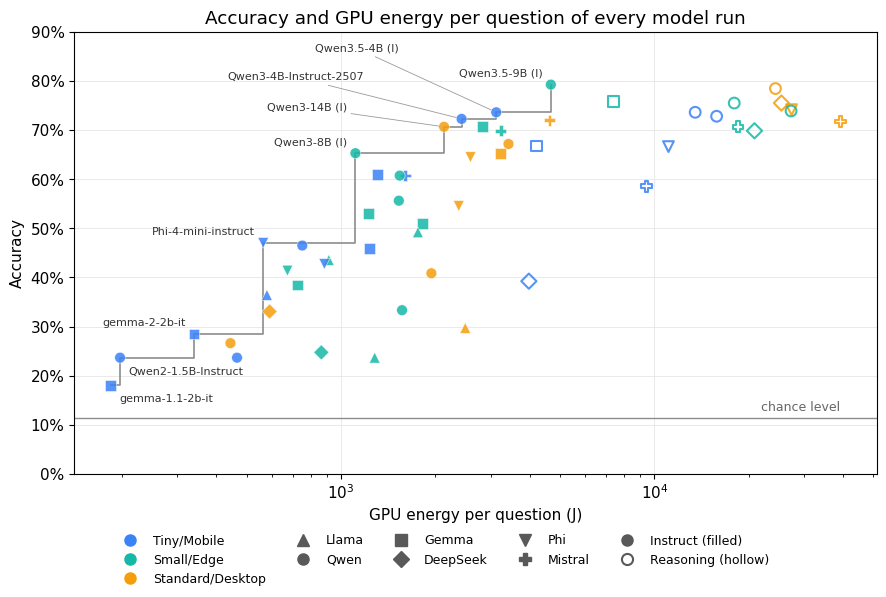

In [3]:
front = pareto_front(model_runs, "gpu_joules_per_question", "accuracy")

fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(CHANCE_LEVEL, color="0.55", linewidth=1)
ax.text(model_runs["gpu_joules_per_question"].max(), CHANCE_LEVEL + 0.008, "chance level", ha="right", va="bottom", color="0.4", fontsize=9)
ax.plot(front["gpu_joules_per_question"], front["accuracy"], drawstyle="steps-post", color="0.55", linewidth=1.2, zorder=1)
scatter_model_runs(ax, model_runs, "gpu_joules_per_question", "accuracy", zorder=2)

# Labels of the model runs on the front, moved aside where the points are close together
OFFSETS = {
    "gemma-1.1-2b-it": (6, -12),
    "Qwen2-1.5B-Instruct": (6, -12),
    "Qwen3-14B (I)": (-70, 14),
    "Qwen3-4B-Instruct-2507": (-70, 30),
    "Qwen3.5-4B (I)": (-70, 46),
}
for _, run in front.iterrows():
    name = short_name(run["model_run"])
    dx, dy = OFFSETS.get(name, (-6, 6))
    ax.annotate(
        name,
        (run["gpu_joules_per_question"], run["accuracy"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        va="center" if abs(dx) > 20 else "baseline",
        fontsize=8,
        color="0.2",
        arrowprops=dict(arrowstyle="-", color="0.6", linewidth=0.6, shrinkA=1, shrinkB=4) if abs(dx) > 20 else None,
    )

ax.set_xscale("log")
ax.set_ylim(0, 0.9)
percent_axis(ax.yaxis)
ax.set_xlabel("GPU energy per question (J)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy and GPU energy per question of every model run")
fig.legend(handles=legend_handles(families=FAMILIES), loc="lower center", ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1))
save_chart(fig, "overview-accuracy-energy")
plt.show()

### 3. Pareto Front and Knee
We list the model runs on the Pareto front, for which no other run is both cheaper and more accurate. The knee is the point of the front farthest from the line joining its two ends, with the energy on a log scale and both axes scaled to the range of the front.

In [4]:
front = front.copy()
x = np.log10(front["gpu_joules_per_question"])
x = (x - x.min()) / (x.max() - x.min())
y = (front["accuracy"] - front["accuracy"].min()) / (front["accuracy"].max() - front["accuracy"].min())
# Distance of each point to the line from (0, 0) to (1, 1)
front["distance_to_chord"] = (y - x) / np.sqrt(2)
knee = front.loc[front["distance_to_chord"].idxmax()]

front_table = front[["model_run", "category", "mode", "release_date", "accuracy", "gpu_joules_per_question", "correct_answers_per_kj", "distance_to_chord"]].copy()
front_table["release_date"] = front_table["release_date"].dt.date
print(f"Model runs on the Pareto front: {len(front)} of {len(model_runs)}   reasoning runs among them: {(front['mode'] == 'Reasoning').sum()}")
print(f"Knee of the front: {knee['model_run']}")
front_table.round({"accuracy": 3, "gpu_joules_per_question": 0, "correct_answers_per_kj": 3, "distance_to_chord": 3}).reset_index(drop=True)

Model runs on the Pareto front: 9 of 53   reasoning runs among them: 0
Knee of the front: Qwen/Qwen3-8B (Instruct Mode)


,model_run,category,mode,release_date,accuracy,gpu_joules_per_question,correct_answers_per_kj,distance_to_chord
0,google/gemma-1.1-2b-it,Tiny/Mobile,Instruct,2024-03-26,0.180,184.0,0.988,0.000
1,Qwen/Qwen2-1.5B-Instruct,Tiny/Mobile,Instruct,2024-06-03,0.237,197.0,1.210,0.050
2,google/gemma-2-2b-it,Tiny/Mobile,Instruct,2024-07-16,0.285,339.0,0.835,-0.013
3,microsoft/Phi-4-mini-instruct,Tiny/Mobile,Instruct,2025-02-19,0.470,564.0,0.833,0.090
4,Qwen/Qwen3-8B (Instruct Mode),Small/Edge,Instruct,2025-04-27,0.653,1111.0,0.588,0.153
5,Qwen/Qwen3-14B (Instruct Mode),Standard/Desktop,Instruct,2025-04-27,0.707,2131.0,0.332,0.072
6,Qwen/Qwen3-4B-Instruct-2507,Tiny/Mobile,Instruct,2025-08-05,0.723,2425.0,0.298,0.063
7,Qwen/Qwen3.5-4B (Instruct Mode),Tiny/Mobile,Instruct,2026-02-27,0.737,3127.0,0.236,0.023
8,Qwen/Qwen3.5-9B (Instruct Mode),Small/Edge,Instruct,2026-02-27,0.793,4671.0,0.170,0.000


### 4. Standout Models
Most accurate, least and most energy per question, most correct answers per kJ, the knee of the front, and the most accurate model run under each energy budget.

In [5]:
def describe(run):
    return {
        "Model run": short_name(run["model_run"]),
        "Category": run["category"],
        "Accuracy": round(run["accuracy"], 3),
        "GPU energy per question (J)": round(run["gpu_joules_per_question"]),
        "Correct answers per kJ": round(run["correct_answers_per_kj"], 3),
    }



headline = {
    "Most accurate": model_runs.loc[model_runs["accuracy"].idxmax()],
    "Least energy per question": model_runs.loc[model_runs["gpu_joules_per_question"].idxmin()],
    "Most energy per question": model_runs.loc[model_runs["gpu_joules_per_question"].idxmax()],
    "Most correct answers per kJ": model_runs.loc[model_runs["correct_answers_per_kj"].idxmax()],
    "Knee of the Pareto front": knee,
}
for budget in BUDGETS_KJ:
    affordable = model_runs[model_runs["gpu_joules_per_question"] <= budget * 1000]
    headline[f"Most accurate under {budget:g} kJ per question"] = affordable.loc[affordable["accuracy"].idxmax()]

pd.DataFrame({title: describe(run) for title, run in headline.items()}).T

,Model run,Category,Accuracy,GPU energy per question (J),Correct answers per kJ
Most accurate,Qwen3.5-9B (I),Small/Edge,0.793,4671,0.17
Least energy per question,gemma-1.1-2b-it,Tiny/Mobile,0.18,184,0.988
Most energy per question,Ministral-3-14B-Reasoning-2512,Standard/Desktop,0.718,39243,0.018
Most correct answers per kJ,Qwen2-1.5B-Instruct,Tiny/Mobile,0.237,197,1.21
Knee of the Pareto front,Qwen3-8B (I),Small/Edge,0.653,1111,0.588
Most accurate under 0.5 kJ per question,gemma-2-2b-it,Tiny/Mobile,0.285,339,0.835
Most accurate under 1 kJ per question,Phi-4-mini-instruct,Tiny/Mobile,0.47,564,0.833
Most accurate under 2 kJ per question,Qwen3-8B (I),Small/Edge,0.653,1111,0.588
Most accurate under 5 kJ per question,Qwen3.5-9B (I),Small/Edge,0.793,4671,0.17


### 5. Total Energy per Model Run
GPU energy consumed by each model run over all its repetitions, and its split between operating modes.

In [6]:
totals = model_runs.assign(total_gpu_kwh=model_runs["total_gpu_joules"] / 3.6e6, inference_hours=model_runs["total_inference_seconds"] / 3600)
most = totals.loc[totals["total_gpu_kwh"].idxmax()]
least = totals.loc[totals["total_gpu_kwh"].idxmin()]
print(f"Most GPU energy:  {short_name(most['model_run'])}: {most['total_gpu_kwh']:.1f} kWh in {most['inference_hours']:.1f} hours of inference ({most['repetitions']} repetitions)")
print(f"Least GPU energy: {short_name(least['model_run'])}: {least['total_gpu_kwh']:.2f} kWh in {least['inference_hours']:.2f} hours of inference ({least['repetitions']} repetitions)")
print(f"Ratio between the two: {most['total_gpu_kwh'] / least['total_gpu_kwh']:.0f} times")

by_mode = totals.groupby("mode")[["total_gpu_kwh", "inference_hours"]].sum()
by_mode["share of the GPU energy (%)"] = 100 * by_mode["total_gpu_kwh"] / by_mode["total_gpu_kwh"].sum()
by_mode.round(1)

Most GPU energy:  Ministral-3-14B-Reasoning-2512: 40.6 kWh in 133.8 hours of inference (10 repetitions)
Least GPU energy: gemma-1.1-2b-it: 0.19 kWh in 0.69 hours of inference (10 repetitions)
Ratio between the two: 213 times


,total_gpu_kwh,inference_hours,share of the GPU energy (%)
mode,,,
Instruct,60.5,204.9,18.0
Reasoning,275.2,920.1,82.0


### 6. Repeatability
We compare the repetitions of each model run. Two repetitions gave the same responses when they generated the same number of tokens for every question. The model runs are split into three groups: those with the same responses in every repetition, those whose responses only changed between repetitions with a different number of warm-up prompts, and those whose responses changed between repetitions with the same number of warm-up prompts. The figure shows the total GPU energy of each repetition, relative to the median of its model run. The model runs of the first group are drawn together in one box.

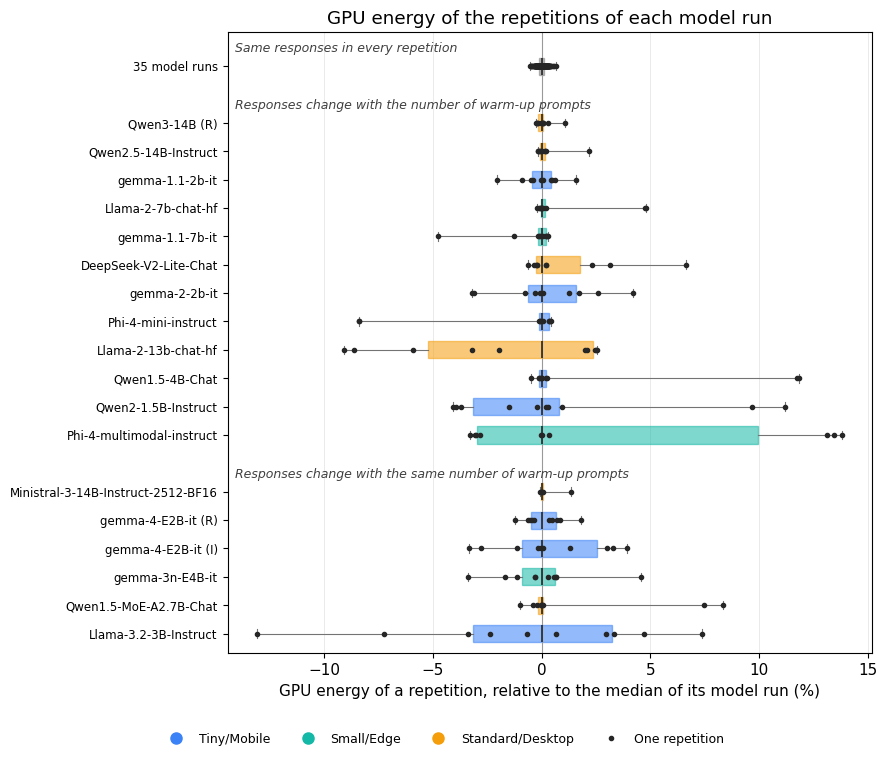

Repetitions per model run: {10: 50, 5: 3} (number of repetitions: model runs)
Warm-up prompts of a repetition: 15 in 89% of the 515 repetitions, and up to 102
group                           Same responses in every repetition  Responses change with the number of warm-up prompts  Responses change with the same number of warm-up prompts
model_runs                                                   35.00                                                12.00                                                      6.00
energy_spread_median                                          0.48                                                 7.34                                                      7.61
energy_spread_max                                             1.00                                                17.14                                                     20.47
energy_per_token_spread_median                                0.48                                                 0.76          

repetitions  \
group                                              model                                             
Responses change with the number of warm-up pro... Qwen3-14B (R)                                10   
                                                   Qwen2.5-14B-Instruct                         10   
                                                   gemma-1.1-2b-it                              10   
                                                   Llama-2-7b-chat-hf                           10   
                                                   gemma-1.1-7b-it                              10   
                                                   DeepSeek-V2-Lite-Chat                        10   
                                                   gemma-2-2b-it                                10   
                                                   Phi-4-mini-instruct                          10   
                                                   Llama-2-13b-chat-hf                          10   
                                                   Qwen1.5-4B-Chat                              10   
                                                   Qwen2-1.5B-Instruct                          10   
                                                   Phi-4-multimodal-instruct                    10   
Responses change with the same number of warm-u... Ministral-3-14B-Instruct-2512-BF16            5   
                                                   gemma-4-E2B-it (R)                           10   
                                                   gemma-4-E2B-it (I)                           10   
                                                   gemma-3n-E4B-it                              10   
                                                   Qwen1.5-MoE-A2.7B-Chat                       10   
                                                   Llama-3.2-3B-Instruct                        10   

                                                                                       different_responses  \
group                                              model                                                     
Responses change with the number of warm-up pro... Qwen3-14B (R)                                         2   
                                                   Qwen2.5-14B-Instruct                                  2   
                                                   gemma-1.1-2b-it                                      10   
                                                   Llama-2-7b-chat-hf                                    2   
                                                   gemma-1.1-7b-it                                       4   
                                                   DeepSeek-V2-Lite-Chat                                 4   
                                                   gemma-2-2b-it                                         7   
                                                   Phi-4-mini-instruct                                   3   
                                                   Llama-2-13b-chat-hf                                   5   
                                                   Qwen1.5-4B-Chat                                       3   
                                                   Qwen2-1.5B-Instruct                                   6   
                                                   Phi-4-multimodal-instruct                             3   
Responses change with the same number of warm-u... Ministral-3-14B-Instruct-2512-BF16                    2   
                                                   gemma-4-E2B-it (R)                                   10   
                                                   gemma-4-E2B-it (I)                                   10   
                                                   gemma-3n-E4B-it                                      10   
                                                   Qwen1.5-MoE-A2.

In [7]:
GROUPS = [
    "Same responses in every repetition",
    "Responses change with the number of warm-up prompts",
    "Responses change with the same number of warm-up prompts",
]

# Responses of a repetition: the number of tokens generated for each question
tokens = inferences.pivot(index=["model_run", "repetition"], columns="question_id", values="generated_tokens")
responses = pd.Series(pd.util.hash_pandas_object(tokens, index=False).to_numpy(), index=tokens.index, name="responses")
repeats = repetitions.merge(responses.reset_index(), on=["model_run", "repetition"], validate="one_to_one")
repeats["relative_energy"] = 100 * (repeats["total_inference_gpu_joules"] / repeats.groupby("model_run")["total_inference_gpu_joules"].transform("median") - 1)


def group_of(runs):
    if runs["responses"].nunique() == 1:
        return GROUPS[0]
    same_warmup = runs.groupby("warmup_prompts")["responses"].nunique()
    return GROUPS[1] if (same_warmup == 1).all() else GROUPS[2]


def spread(values):
    # Difference between the highest and the lowest value, relative to the median (%)
    return 100 * (values.max() - values.min()) / values.median()


repeatability = repeats.groupby("model_run").agg(
    repetitions=("repetition", "size"),
    different_responses=("responses", "nunique"),
    fewest_warmup_prompts=("warmup_prompts", "min"),
    most_warmup_prompts=("warmup_prompts", "max"),
    energy_spread=("total_inference_gpu_joules", spread),
    energy_per_token_spread=("gpu_joules_per_generated_token", spread),
    accuracy_range=("avg_accuracy", lambda values: 100 * (values.max() - values.min())),
)
repeatability["group"] = repeats.groupby("model_run").apply(group_of, include_groups=False)
repeatability = repeatability.merge(model_runs[["model_run", "category"]], left_index=True, right_on="model_run").set_index("model_run")

# One row for the first group and one row per model run of the other two, from the bottom of the chart to the top,
# with an empty row between the groups for their names
first_group = repeatability.index[repeatability["group"] == GROUPS[0]]
rows, position = [], 0
for group in GROUPS[:0:-1]:
    for model_run, run in repeatability[repeatability["group"] == group].sort_values("energy_spread", ascending=False).iterrows():
        rows.append((position, group, short_name(model_run), repeats.loc[repeats["model_run"] == model_run, "relative_energy"], CATEGORY_COLORS[run["category"]]))
        position += 1
    position += 1
rows.append((position, GROUPS[0], f"{len(first_group)} model runs", repeats.loc[repeats["model_run"].isin(first_group), "relative_energy"], "0.5"))

fig, ax = plt.subplots(figsize=(9, 0.27 * position + 2.2))
positions = [row[0] for row in rows]
boxes = ax.boxplot(
    [values for _, _, _, values, _ in rows],
    positions=positions,
    orientation="horizontal",
    whis=(0, 100),
    widths=0.6,
    patch_artist=True,
    medianprops=dict(color="0.15", linewidth=1.2),
    whiskerprops=dict(color="0.45", linewidth=0.8),
    capprops=dict(color="0.45", linewidth=0.8),
)
for box, (row_position, _, _, values, color) in zip(boxes["boxes"], rows):
    box.set(facecolor=color, edgecolor=color, alpha=0.55)
    ax.scatter(values, np.full(len(values), row_position), s=9, color="0.15", zorder=3)
ax.set_yticks(positions, labels=[name for _, _, name, _, _ in rows], fontsize=8.5)
# Name of each group, above its rows
for group in GROUPS:
    top = max(row_position for row_position, row_group, _, _, _ in rows if row_group == group)
    ax.text(0.012, top + 0.62, group, transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=9, color="0.25", style="italic")
ax.set_ylim(-0.7, position + 1.2)
ax.axvline(0, color="0.6", linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("GPU energy of a repetition, relative to the median of its model run (%)")
ax.set_title("GPU energy of the repetitions of each model run")
fig.legend(handles=legend_handles(modes=False) + [Line2D([], [], marker="o", linestyle="", markersize=3, color="0.15", label="One repetition")], loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
save_chart(fig, "overview-repeatability")
plt.show()

print(f"Repetitions per model run: {model_runs['repetitions'].value_counts().sort_index(ascending=False).to_dict()} (number of repetitions: model runs)")
fewest = repeats["warmup_prompts"].min()
print(f"Warm-up prompts of a repetition: {fewest} in {100 * (repeats['warmup_prompts'] == fewest).mean():.0f}% of the {len(repeats)} repetitions, and up to {repeats['warmup_prompts'].max()}")
by_group = repeatability.groupby("group").agg(
    model_runs=("repetitions", "size"),
    energy_spread_median=("energy_spread", "median"),
    energy_spread_max=("energy_spread", "max"),
    energy_per_token_spread_median=("energy_per_token_spread", "median"),
    energy_per_token_spread_max=("energy_per_token_spread", "max"),
    accuracy_range_median=("accuracy_range", "median"),
    accuracy_range_max=("accuracy_range", "max"),
    most_warmup_prompts=("most_warmup_prompts", "max"),
).reindex(GROUPS)
print(by_group.round(2).T.to_string())
varying = repeatability[repeatability["group"] != GROUPS[0]]
print(f"\nModel runs whose responses vary: {len(varying)}; spread of their GPU energy: median {varying['energy_spread'].median():.1f}%, largest {varying['energy_spread'].max():.1f}%; range of their accuracy: median {varying['accuracy_range'].median():.1f} points, largest {varying['accuracy_range'].max():.1f} points")
repeatability[repeatability["group"] != GROUPS[0]].sort_values(["group", "energy_spread"]).assign(model=lambda table: table.index.map(short_name)).set_index(["group", "model"]).drop(columns="category").round(2)

### 7. Temperature of the Hardware
The temperatures of the GPU and of the CPU are read after each inference. We follow them along the 372 questions of a run, as the mean over the runs of each operating mode and size category, and give for each group the median over its model runs of the temperature after the first question, of the average over the run and of the maximum.

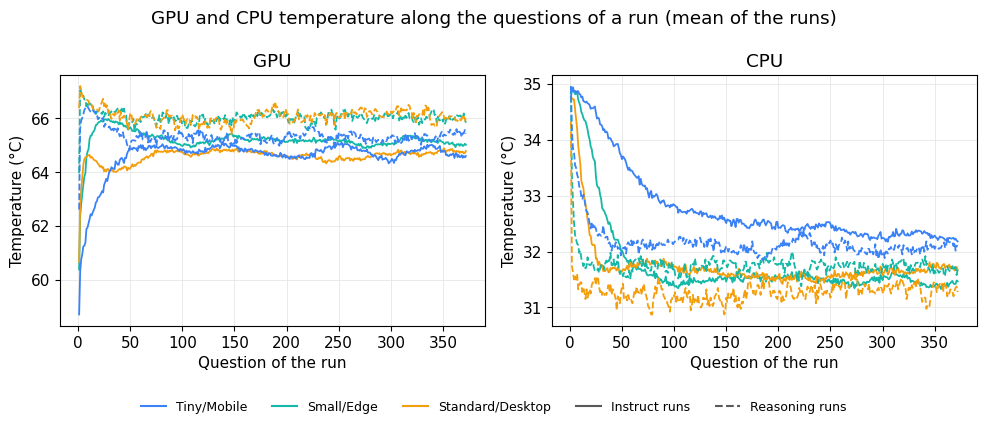

Average GPU temperature of a run: 59.7 to 66.9 °C, maximum 69 °C
Average CPU temperature of a run: 29.6 to 36.2 °C, maximum 44 °C
Minutes until the GPU is within 1 °C of its final temperature: median 0.6, at most 4.7
Rank correlation between the average GPU temperature of a model run and its GPU power: 0.73


gpu_after_first_question  gpu_average  \
mode      category                                                  
Instruct  Tiny/Mobile                           59.0         64.7   
          Small/Edge                            61.0         65.3   
          Standard/Desktop                      62.0         65.3   
Reasoning Tiny/Mobile                           63.0         65.5   
          Small/Edge                            64.0         66.2   
          Standard/Desktop                      66.5         66.2   

                            gpu_maximum  cpu_after_first_question  \
mode      category                                                  
Instruct  Tiny/Mobile              67.0                      35.0   
          Small/Edge               67.0                      35.0   
          Standard/Desktop         68.0                      35.0   
Reasoning Tiny/Mobile              67.5                      35.0   
          Small/Edge               68.0                      35.0   
          Standard/Desktop         68.0                      34.5   

                            cpu_average  cpu_maximum  
mode      category                                    
Instruct  Tiny/Mobile              32.7         36.0  
          Small/Edge               31.6         35.0  
          Standard/Desktop         31.0         35.0  
Reasoning Tiny/Mobile              32.0         35.0  
          Small/Edge               31.7         35.0  
          Standard/Desktop         31.3         34.5

In [8]:
# Position of each inference in its run, in the order in which the questions were answered
inferences["position"] = inferences.groupby(["execution", "run", "model_run"]).cumcount() + 1
inferences["elapsed_minutes"] = inferences.groupby(["execution", "run", "model_run"])["inference_time_seconds"].cumsum() / 60
temperatures = inferences.merge(model_runs[["model_run", "category", "mode"]], on="model_run")
TEMPERATURES = {"GPU": "gpu_temperature_celsius", "CPU": "cpu_temperature_celsius"}

by_position = temperatures.groupby(["mode", "category", "position"])[list(TEMPERATURES.values())].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, (name, column) in zip(axes, TEMPERATURES.items()):
    for (mode, category), group in by_position.groupby(["mode", "category"]):
        ax.plot(group["position"], group[column], color=CATEGORY_COLORS[category], linestyle="-" if mode == "Instruct" else "--", linewidth=1.3)
    ax.set_title(name)
    ax.set_xlabel("Question of the run")
    ax.set_ylabel("Temperature (°C)")
handles = [Line2D([], [], color=CATEGORY_COLORS[category], label=category) for category in CATEGORY_ORDER]
handles += [Line2D([], [], color="0.35", label="Instruct runs"), Line2D([], [], color="0.35", linestyle="--", label="Reasoning runs")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle("GPU and CPU temperature along the questions of a run (mean of the runs)")
plt.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "overview-temperature-during-runs")
plt.show()

# Temperature of each run, summarized per model run (median of its repetitions) and per group (median of its model runs)
run_temperatures = temperatures.groupby(["execution", "run", "model_run", "mode", "category"]).agg(
    gpu_after_first_question=("gpu_temperature_celsius", "first"),
    gpu_average=("gpu_temperature_celsius", "mean"),
    gpu_maximum=("gpu_temperature_celsius", "max"),
    cpu_after_first_question=("cpu_temperature_celsius", "first"),
    cpu_average=("cpu_temperature_celsius", "mean"),
    cpu_maximum=("cpu_temperature_celsius", "max"),
).reset_index()
per_model_run = run_temperatures.groupby(["model_run", "mode", "category"]).median(numeric_only=True).reset_index()


def plateau(run):
    # Minutes until the GPU is within 1 °C of the median temperature of the last tenth of the run
    final = run["gpu_temperature_celsius"].iloc[int(0.9 * len(run)):].median()
    return run.loc[run["gpu_temperature_celsius"] >= final - 1, "elapsed_minutes"].iloc[0]


minutes = temperatures.groupby(["execution", "run", "model_run"]).apply(plateau, include_groups=False)
print(f"Average GPU temperature of a run: {run_temperatures['gpu_average'].min():.1f} to {run_temperatures['gpu_average'].max():.1f} °C, maximum {run_temperatures['gpu_maximum'].max()} °C")
print(f"Average CPU temperature of a run: {run_temperatures['cpu_average'].min():.1f} to {run_temperatures['cpu_average'].max():.1f} °C, maximum {run_temperatures['cpu_maximum'].max()} °C")
print(f"Minutes until the GPU is within 1 °C of its final temperature: median {minutes.median():.1f}, at most {minutes.max():.1f}")
print(f"Rank correlation between the average GPU temperature of a model run and its GPU power: {per_model_run.merge(model_runs[['model_run', 'gpu_power_watts']])[['gpu_average', 'gpu_power_watts']].corr(method='spearman').iloc[0, 1]:.2f}")

temperature_table = per_model_run.groupby(["mode", "category"]).median(numeric_only=True)
temperature_table = temperature_table.reindex([(mode, category) for mode in ["Instruct", "Reasoning"] for category in CATEGORY_ORDER])
temperature_table.round(1)

We plot the average GPU and CPU temperature of every run of the main execution in the order in which the runs were executed, and measure how far each run is from the median of the runs of the same model run.

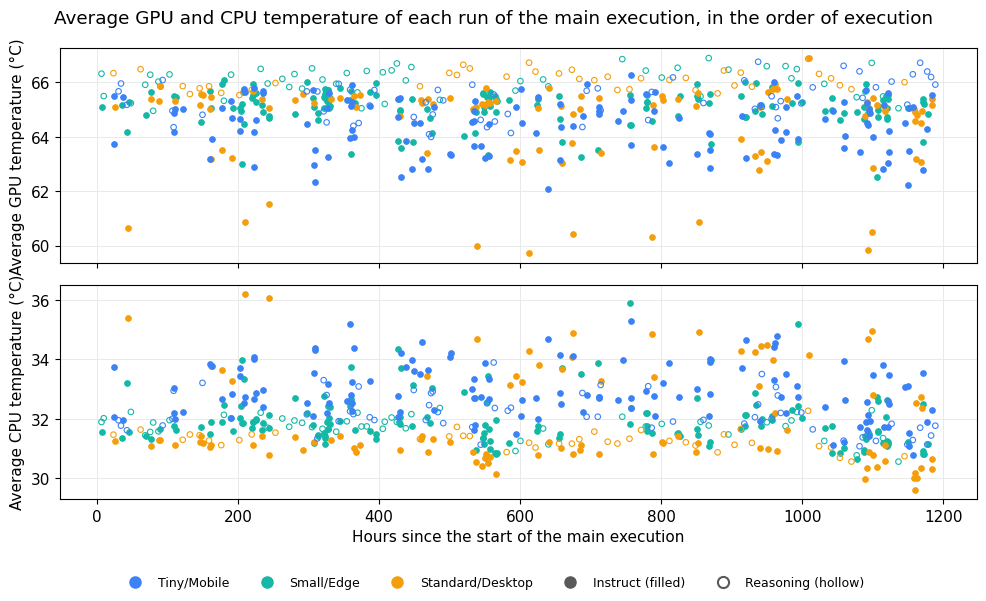

Runs: 530   hours: 1189
GPU: average temperature of a run 59.7 to 66.9 °C; difference from the median of its model run: median 0.21 °C, -1.18 to +1.42 °C; rank correlation with the order of execution -0.08 (p = 0.064)
CPU: average temperature of a run 29.6 to 36.2 °C; difference from the median of its model run: median 0.21 °C, -1.33 to +3.15 °C; rank correlation with the order of execution -0.34 (p = 0.000)


In [9]:
from scipy.stats import spearmanr

from common import load_run_table

run_table = load_run_table("main")
run_table["order"] = np.arange(len(run_table))
run_table["hours"] = run_table["runtime_seconds"].cumsum() / 3600
groups = load_model_runs(include_superseded=True).set_index("model_run")[["category", "mode"]]
run_table = run_table.join(groups, on="model")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (name, column) in zip(axes, {"GPU": "avg_gpu_temperature_celsius", "CPU": "avg_cpu_temperature_celsius"}.items()):
    for (category, mode), group in run_table.groupby(["category", "mode"]):
        color = CATEGORY_COLORS[category]
        ax.scatter(group["hours"], group[column], s=16, linewidth=0.8, facecolors=color if mode == "Instruct" else "none", edgecolors=color)
    ax.set_ylabel(f"Average {name} temperature (°C)")
axes[1].set_xlabel("Hours since the start of the main execution")
handles = legend_handles()
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle("Average GPU and CPU temperature of each run of the main execution, in the order of execution")
plt.tight_layout(rect=(0, 0.06, 1, 1))
save_chart(fig, "overview-temperature-over-execution")
plt.show()

print(f"Runs: {len(run_table)}   hours: {run_table['hours'].max():.0f}")
for name, column in {"GPU": "avg_gpu_temperature_celsius", "CPU": "avg_cpu_temperature_celsius"}.items():
    deviation = run_table[column] - run_table.groupby("model")[column].transform("median")
    correlation, p_value = spearmanr(run_table["order"], deviation)
    print(f"{name}: average temperature of a run {run_table[column].min():.1f} to {run_table[column].max():.1f} °C; difference from the median of its model run: median {deviation.abs().median():.2f} °C, {deviation.min():+.2f} to {deviation.max():+.2f} °C; rank correlation with the order of execution {correlation:+.2f} (p = {p_value:.3f})")

### 8. Key Values

In [10]:
most_accurate = headline["Most accurate"]
cheapest = headline["Least energy per question"]
costliest = headline["Most energy per question"]
efficient = headline["Most correct answers per kJ"]

print(f"Model runs analysed: {len(model_runs)} ({(model_runs['mode'] == 'Instruct').sum()} instruct, {(model_runs['mode'] == 'Reasoning').sum()} reasoning), from {model_runs['model'].nunique()} models")
print(f"Accuracy: {model_runs['accuracy'].min():.3f} to {model_runs['accuracy'].max():.3f} ({model_runs['accuracy'].max() / model_runs['accuracy'].min():.1f} times)")
print(f"GPU energy per question: {model_runs['gpu_joules_per_question'].min():.0f} J to {model_runs['gpu_joules_per_question'].max():.0f} J ({model_runs['gpu_joules_per_question'].max() / model_runs['gpu_joules_per_question'].min():.0f} times)")
print(f"Most accurate: {short_name(most_accurate['model_run'])} ({most_accurate['accuracy']:.3f}, {most_accurate['gpu_joules_per_question']:.0f} J per question)")
print(f"Least energy per question: {short_name(cheapest['model_run'])} ({cheapest['gpu_joules_per_question']:.0f} J, accuracy {cheapest['accuracy']:.3f})")
print(f"Most energy per question: {short_name(costliest['model_run'])} ({costliest['gpu_joules_per_question']:.0f} J, accuracy {costliest['accuracy']:.3f})")
print(f"Most correct answers per kJ: {short_name(efficient['model_run'])} ({efficient['correct_answers_per_kj']:.2f}, accuracy {efficient['accuracy']:.3f})")
print(f"Pareto front: {len(front)} model runs, {(front['mode'] == 'Reasoning').sum()} of them reasoning runs; knee: {short_name(knee['model_run'])}")
ranks = model_runs[["correct_answers_per_kj", "accuracy", "gpu_joules_per_question"]].rank()
print(f"Rank correlation of accuracy per joule with accuracy: {ranks['correct_answers_per_kj'].corr(ranks['accuracy']):.2f}; with energy per question: {ranks['correct_answers_per_kj'].corr(ranks['gpu_joules_per_question']):.2f}")
print("Repeatability, by group of model runs:")
print(by_group.round(2).T.to_string())

Model runs analysed: 53 (38 instruct, 15 reasoning), from 47 models
Accuracy: 0.180 to 0.793 (4.4 times)
GPU energy per question: 184 J to 39243 J (213 times)
Most accurate: Qwen3.5-9B (I) (0.793, 4671 J per question)
Least energy per question: gemma-1.1-2b-it (184 J, accuracy 0.180)
Most energy per question: Ministral-3-14B-Reasoning-2512 (39243 J, accuracy 0.718)
Most correct answers per kJ: Qwen2-1.5B-Instruct (1.21, accuracy 0.237)
Pareto front: 9 model runs, 0 of them reasoning runs; knee: Qwen3-8B (I)
Rank correlation of accuracy per joule with accuracy: -0.68; with energy per question: -0.96
Repeatability, by group of model runs:
group                           Same responses in every repetition  Responses change with the number of warm-up prompts  Responses change with the same number of warm-up prompts
model_runs                                                   35.00                                                12.00                                                      6.00